In [2]:
import pandas as pd
import numpy as np
from datetime import datetime
import warnings
warnings.filterwarnings('ignore') # Tắt các cảnh báo đỏ cho sạch màn hình

print("1. Đang nạp dữ liệu từ Excel...")
# Đọc file với đường dẫn cấu trúc mới
df = pd.read_excel("../data/NEKO_Edu_387HS_DayDu_6Sheet.xlsx", sheet_name="DanhSachHocSinh", header=1)
# Xử lý Ngày sinh và Tuổi
df['Ngày sinh'] = pd.to_datetime(df['Ngày sinh'], errors='coerce')
def calculate_age(dob):
    if pd.isna(dob): return 0
    today = datetime.now()
    return today.year - dob.year - ((today.month, today.day) < (dob.month, dob.day))
df['Tuổi'] = df['Ngày sinh'].apply(calculate_age)

print("2. Đang tạo thêm Dữ liệu Hành vi (Feature Engineering)...")
np.random.seed(42)
# Giả lập: Số lần nghe máy và Tỷ lệ mở email
df['So_Lan_Nghe_May'] = np.random.randint(0, 5, size=len(df))
df['Ty_Le_Mo_Email'] = np.random.uniform(0.0, 1.0, size=len(df))

# Khách nào tương tác càng nhiều -> Tỷ lệ chốt càng cao
df['Da_Dang_Ky'] = np.where((df['So_Lan_Nghe_May'] > 2) & (df['Ty_Le_Mo_Email'] > 0.5), 1, 0)
# Thêm nhiễu 15% để AI phải suy nghĩ thay vì học thuộc lòng
noise = np.random.choice([0, 1], size=len(df), p=[0.85, 0.15])
df['Da_Dang_Ky'] = np.where(noise == 1, 1 - df['Da_Dang_Ky'], df['Da_Dang_Ky'])

print("✅ Hoàn tất nạp dữ liệu! Xem trước 5 dòng:")
display(df[['Giới tính', 'Tuổi', 'Level', 'So_Lan_Nghe_May', 'Ty_Le_Mo_Email', 'Da_Dang_Ky']].head())

1. Đang nạp dữ liệu từ Excel...
2. Đang tạo thêm Dữ liệu Hành vi (Feature Engineering)...
✅ Hoàn tất nạp dữ liệu! Xem trước 5 dòng:


,Giới tính,Tuổi,Level,So_Lan_Nghe_May,Ty_Le_Mo_Email,Da_Dang_Ky
0,Nam,5,KINDY,3,0.915214,1
1,Nam,3,KINDY,4,0.442352,0
2,Nam,4,KINDY,2,0.239787,0
3,Nam,3,KINDY,4,0.093873,0
4,Nữ,3,KINDY,4,0.182866,0


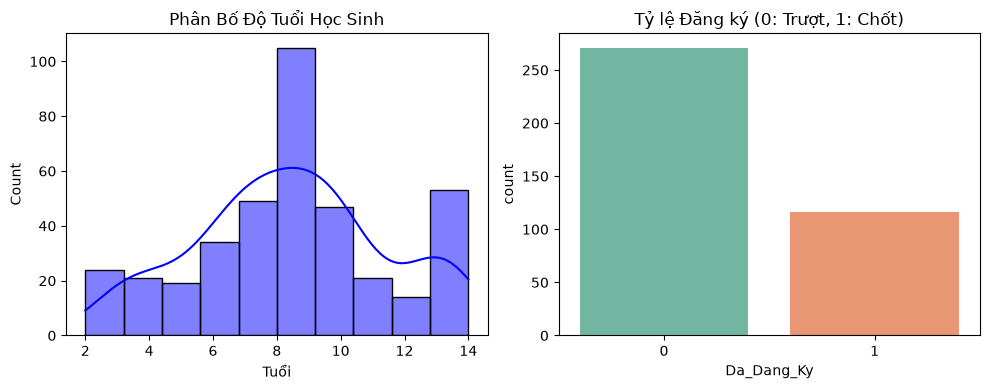

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['Tuổi'], bins=10, kde=True, color='blue')
plt.title("Phân Bố Độ Tuổi Học Sinh")

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Da_Dang_Ky', palette='Set2')
plt.title("Tỷ lệ Đăng ký (0: Trượt, 1: Chốt)")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

print("3. Bắt đầu chuẩn bị huấn luyện AI...")
# Lọc 5 tiêu chí quyết định
X = df[['Giới tính', 'Tuổi', 'Level', 'So_Lan_Nghe_May', 'Ty_Le_Mo_Email']].copy()
y = df['Da_Dang_Ky']

# Dịch chữ sang số
le_gt = LabelEncoder()
le_lv = LabelEncoder()
X['Giới tính'] = le_gt.fit_transform(X['Giới tính'].astype(str))
X['Level'] = le_lv.fit_transform(X['Level'].astype(str))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tính trọng số phạt để chống học vẹt (Imbalanced Data)
trong_so_phat = len(y_train[y_train == 0]) / (len(y_train[y_train == 1]) + 1e-5)

# Cấu hình XGBoost
base_model = XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=trong_so_phat)

param_grid = {
    'max_depth': [3, 4, 5],             
    'learning_rate': [0.05, 0.1], 
    'n_estimators': [100, 200]
}

print("⏳ Đang huấn luyện sâu bằng Grid Search (Sẽ mất vài giây)...")
grid_search = GridSearchCV(estimator=base_model, param_grid=param_grid, cv=3, scoring='accuracy', verbose=0)
grid_search.fit(X_train, y_train)

model = grid_search.best_estimator_
print(f"✅ Đã tìm ra bộ não tối ưu: {grid_search.best_params_}")

3. Bắt đầu chuẩn bị huấn luyện AI...
⏳ Đang huấn luyện sâu bằng Grid Search (Sẽ mất vài giây)...
✅ Đã tìm ra bộ não tối ưu: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


🎯 Độ chính xác của thuật toán: 85.90%



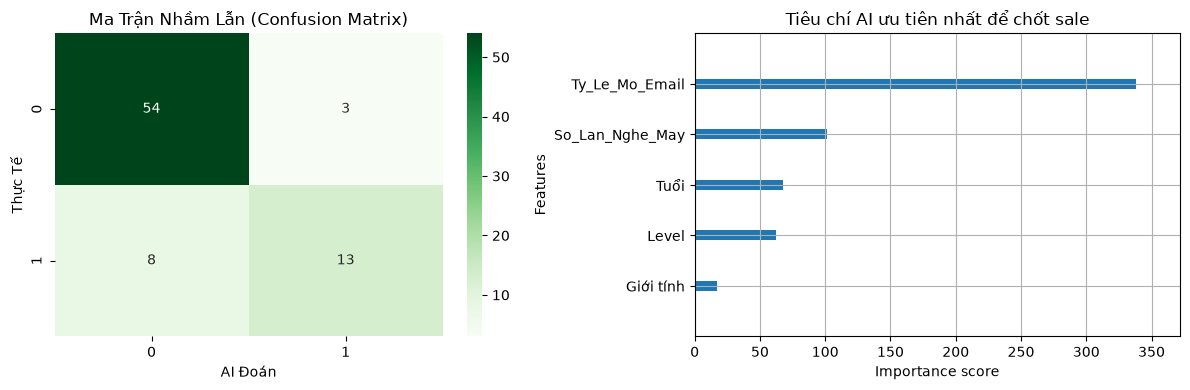


--- TEST THỰC TẾ TRÊN 3 KHÁCH HÀNG MỚI ---
Khách 1 - Nghe máy 1 lần, tỷ lệ mở mail 84%:
 🎯 Khả năng nộp tiền: 8.0% -> ĐỀ XUẤT: ❌ BỎ QUA
Khách 2 - Nghe máy 0 lần, tỷ lệ mở mail 80%:
 🎯 Khả năng nộp tiền: 19.8% -> ĐỀ XUẤT: ❌ BỎ QUA
Khách 3 - Nghe máy 2 lần, tỷ lệ mở mail 96%:
 🎯 Khả năng nộp tiền: 53.5% -> ĐỀ XUẤT: ✅ GỌI NGAY

💾 Đã lưu thành công bộ não AI vào thư mục: models/enrollment_model.pkl


In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix
from xgboost import plot_importance
import joblib

# 1. Chấm điểm tổng thể
y_pred = model.predict(X_test)
print(f"🎯 Độ chính xác của thuật toán: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

# 2. Vẽ Confusion Matrix và Tiêu chí ưu tiên (Feature Importance)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Ma Trận Nhầm Lẫn (Confusion Matrix)")
plt.xlabel("AI Đoán")
plt.ylabel("Thực Tế")

plt.subplot(1, 2, 2)
plot_importance(model, importance_type='weight', ax=plt.gca(), show_values=False)
plt.title("Tiêu chí AI ưu tiên nhất để chốt sale")
plt.tight_layout()
plt.show()

# 3. Test thực tế trên giao diện
print("\n--- TEST THỰC TẾ TRÊN 3 KHÁCH HÀNG MỚI ---")
ca_test = X_test.head(3)
ty_le = model.predict_proba(ca_test)
ket_qua = model.predict(ca_test)

for i in range(len(ca_test)):
    print(f"Khách {i+1} - Nghe máy {ca_test.iloc[i]['So_Lan_Nghe_May']:.0f} lần, tỷ lệ mở mail {ca_test.iloc[i]['Ty_Le_Mo_Email']*100:.0f}%:")
    print(f" 🎯 Khả năng nộp tiền: {ty_le[i][1]*100:.1f}% -> ĐỀ XUẤT: {'✅ GỌI NGAY' if ket_qua[i]==1 else '❌ BỎ QUA'}")

# 4. Xuất file với đường dẫn cấu trúc mới
joblib.dump(model, '../models/enrollment_model.pkl')
print("\n💾 Đã lưu thành công bộ não AI vào thư mục: models/enrollment_model.pkl")

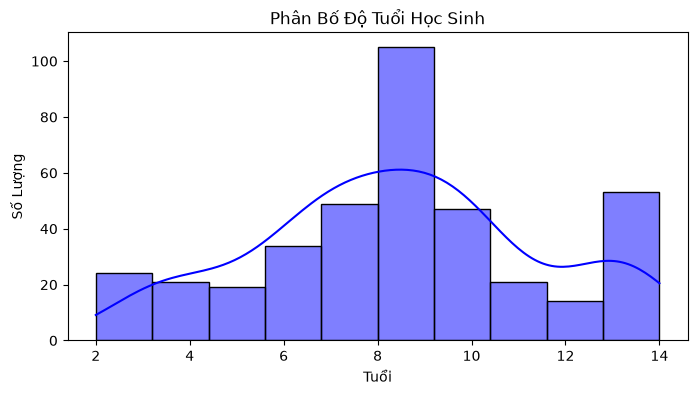

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(df['Tuổi'], bins=10, kde=True, color='blue')
plt.title("Phân Bố Độ Tuổi Học Sinh")
plt.xlabel("Tuổi")
plt.ylabel("Số Lượng")
plt.show() # Code này sẽ vẽ thẳng ra 1 cái biểu đồ ngay dưới ô code

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
import numpy as np

# Giả lập cột "Đã đăng ký" (Thực tế lấy từ SQL)
np.random.seed(42)
df['Da_Dang_Ky'] = np.random.choice([1, 0], size=len(df), p=[0.7, 0.3])

X = df[['Giới tính', 'Tuổi', 'Level']].copy()
y = df['Da_Dang_Ky']

X['Giới tính'] = LabelEncoder().fit_transform(X['Giới tính'].astype(str))
X['Level'] = LabelEncoder().fit_transform(X['Level'].astype(str))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = XGBClassifier(n_estimators=100, max_depth=4, random_state=42)
model.fit(X_train, y_train)
print("AI đã học xong quy luật!")

AI đã học xong quy luật!


Độ chính xác: 66.67%


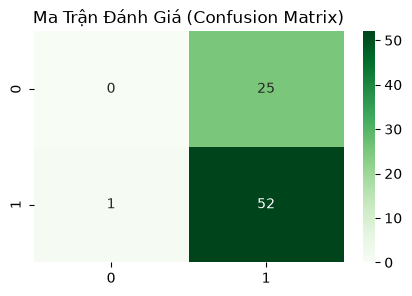

Đã tạo xong file enrollment_model.pkl!


In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix
import joblib

y_pred = model.predict(X_test)
print(f"Độ chính xác: {accuracy_score(y_test, y_pred) * 100:.2f}%")

# Vẽ ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Ma Trận Đánh Giá (Confusion Matrix)")
plt.show()

# Xuất file cho Backend
joblib.dump(model, 'enrollment_model.pkl')
print("Đã tạo xong file enrollment_model.pkl!")

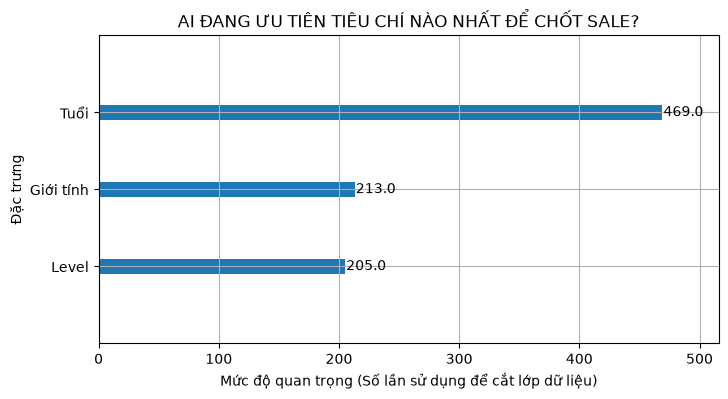


--- TEST THỰC TẾ: BÁC SĨ AI CHUẨN ĐOÁN 3 HỌC SINH ---
Hồ sơ 1 - Thông số kĩ thuật (Giới tính: 0, Tuổi: 11, Level: 5):
 🎯 Tỷ lệ chốt sale thành công do AI tính toán: 94.1%
 📢 Đề xuất: TIỀM NĂNG CAO! Đẩy sang cho nhân viên Telesale gọi ngay.

Hồ sơ 2 - Thông số kĩ thuật (Giới tính: 1, Tuổi: 8, Level: 1):
 🎯 Tỷ lệ chốt sale thành công do AI tính toán: 76.0%
 📢 Đề xuất: TIỀM NĂNG CAO! Đẩy sang cho nhân viên Telesale gọi ngay.

Hồ sơ 3 - Thông số kĩ thuật (Giới tính: 1, Tuổi: 7, Level: 0):
 🎯 Tỷ lệ chốt sale thành công do AI tính toán: 58.9%
 📢 Đề xuất: TIỀM NĂNG CAO! Đẩy sang cho nhân viên Telesale gọi ngay.



In [9]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

# 1. Vẽ biểu đồ "Đọc vị" AI (Feature Importance)
plt.rcParams['figure.figsize'] = [8, 4]
plot_importance(model, importance_type='weight', 
                title='AI ĐANG ƯU TIÊN TIÊU CHÍ NÀO NHẤT ĐỂ CHỐT SALE?', 
                xlabel='Mức độ quan trọng (Số lần sử dụng để cắt lớp dữ liệu)', 
                ylabel='Đặc trưng')
plt.show()

# 2. Bắt AI chạy thử một ca lâm sàng thực tế và giải thích lý do
# Lấy thử 3 bộ hồ sơ đầu tiên trong tập thi (X_test)
ca_test = X_test.head(3)
ket_qua = model.predict(ca_test)
ty_le = model.predict_proba(ca_test)

print("\n--- TEST THỰC TẾ: BÁC SĨ AI CHUẨN ĐOÁN 3 HỌC SINH ---")
for i in range(len(ca_test)):
    print(f"Hồ sơ {i+1} - Thông số kĩ thuật (Giới tính: {ca_test.iloc[i,0]}, Tuổi: {ca_test.iloc[i,1]}, Level: {ca_test.iloc[i,2]}):")
    print(f" 🎯 Tỷ lệ chốt sale thành công do AI tính toán: {ty_le[i][1]*100:.1f}%")
    
    if ket_qua[i] == 1:
        print(" 📢 Đề xuất: TIỀM NĂNG CAO! Đẩy sang cho nhân viên Telesale gọi ngay.\n")
    else:
        print(" 📢 Đề xuất: Tỷ lệ trượt cao, đừng tốn thời gian gọi, hãy đưa vào tool gửi Email tự động.\n")